<a href="https://colab.research.google.com/github/sabbirpuspo/PGCB-Demand-Aware-Smart-Grid-Optimization/blob/main/PGCB_Time_Series_SARIMAX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PGCB Time-Series Analysis with SARIMAX

**Conference paper:** *An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids*

## Purpose
 It follows the logic of the supplied monthly SARIMAX example, but uses the same PGCB source workbook and conservative data-quality rules used in the paper.

The time-series target is **monthly average daily peak demand (MW)**: for each eligible complete 24-hour day, the daily maximum demand is calculated; those daily peaks are then averaged within each month. This keeps the analysis directly related to peak-load management while providing a monthly series with a 12-month seasonal cycle suitable for SARIMAX.

**Important:** This is a complementary forecasting/time-series experiment. It does not replace the hourly Ridge model used by UAD-WF unless a later experiment explicitly does so. The 2024 period has already been inspected elsewhere in the project, so this should be described as an additional retrospective experiment, not a pristine untouched holdout.

## 1. Runtime and scientific libraries
Import the packages needed for data handling, the Augmented Dickey-Fuller (ADF) stationarity test, SARIMAX modeling, residual diagnostics, forecasting metrics, and publication-quality figures.

In [1]:
import hashlib
import io
import itertools
import json
import os
import platform
import shutil
import sys
import time
import uuid
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings('ignore')
SEED = 20261111
np.random.seed(SEED)
IS_COLAB = 'google.colab' in sys.modules

print('Runtime:', 'Google Colab' if IS_COLAB else 'local Python')
print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| statsmodels:', statsmodels.__version__)

Runtime: Google Colab
Python: 3.13.16
pandas: 2.2.3 | statsmodels: 0.15.0


## 2. Experiment settings and output folder
The notebook saves every result into a new timestamped folder so earlier experiments are never overwritten. All manuscript-oriented figures are exported as **600-DPI PNG** and **vector PDF**.

The first incomplete month in the source release is excluded. The modeling window is May 2015-December 2024, with **2015-2023 used for model fitting/order selection** and the 12 months of **2024 used for retrospective evaluation**.

In [2]:
USE_GOOGLE_DRIVE = True
DATASET_FILENAME = 'PGCB_date_power_demand.xlsx'
UCI_ARCHIVE_URL = (
    'https://archive.ics.uci.edu/static/public/1175/'
    'pgcb%2Bhourly%2Bgeneration%2Bdataset%2B%28bangladesh%29.zip'
)
DEMAND_LIMITS_MW = (1000.0, 30000.0)
GENERATION_LIMITS_MW = (0.0, 30000.0)
MONTHLY_START = pd.Timestamp('2015-05-01')
TRAIN_END = pd.Timestamp('2023-12-01')
TEST_START = pd.Timestamp('2024-01-01')
TEST_END = pd.Timestamp('2024-12-01')
SEASONAL_PERIOD = 12
MIN_ELIGIBLE_DAYS_PER_MONTH = 10
FIG_DPI = 600

if IS_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/PGCB_Demand_Optimization')
elif IS_COLAB:
    PROJECT_DIR = Path('/content/PGCB_Demand_Optimization')
else:
    PROJECT_DIR = Path(os.environ.get('PGCB_PROJECT_DIR', '/mnt/data/PGCB_Demand_Optimization'))

DATA_DIR = PROJECT_DIR / 'data'
RUN_ID = ('sarimax_timeseries_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
          + '_' + uuid.uuid4().hex[:6])
OUT_DIR = PROJECT_DIR / 'runs' / RUN_ID
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=False)

print('Run ID:', RUN_ID)
print('Output directory:', OUT_DIR)

Mounted at /content/drive
Run ID: sarimax_timeseries_20261111T063546Z_0a80f1
Output directory: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/sarimax_timeseries_20261111T063546Z_0a80f1


## 3. Load the original PGCB workbook with provenance
Reuse the official UCI PGCB workbook. If it is already in the project data folder, the cached file is used; otherwise, the official UCI archive is downloaded. A SHA-256 fingerprint is saved so the exact source file can be identified later.

In [3]:
DATA_PATH = DATA_DIR / DATASET_FILENAME
local_override = os.environ.get('PGCB_LOCAL_XLSX') if not IS_COLAB else None
if local_override:
    DATA_PATH = Path(local_override)

if not DATA_PATH.exists():
    print('Cached workbook not found; downloading from the UCI repository...')
    response = requests.get(UCI_ARCHIVE_URL, timeout=180)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        members = [name for name in archive.namelist()
                   if name.lower().endswith('pgcb_date_power_demand.xlsx')]
        if len(members) != 1:
            raise RuntimeError(f'Expected one PGCB workbook; found: {members}')
        staged = DATA_DIR / (DATASET_FILENAME + '.partial')
        try:
            with archive.open(members[0]) as src, staged.open('wb') as dst:
                shutil.copyfileobj(src, dst)
            staged.replace(DATA_PATH)
        finally:
            staged.unlink(missing_ok=True)

SOURCE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_excel(
    DATA_PATH,
    engine='openpyxl',
    usecols=['datetime', 'demand_mw', 'generation_mw', 'load_shedding']
)
print('Rows loaded:', len(raw))
print('Source SHA-256:', SOURCE_SHA256)

Rows loaded: 92650
Source SHA-256: cd10a95b98033594b70ff176d69e9feaa2ade5f43b8ae4e5640a0f9deabc9da1


## 4. Apply the same conservative data-quality rules used in the paper
Remove ambiguous duplicate timestamps, off-hour measurements, and broad out-of-range demand/generation values. Only days with exactly 24 unique hourly observations are retained before daily peak demand is calculated. This keeps the time-series experiment consistent with the paper's existing 2024 validation protocol.

In [4]:
working = raw.copy()
working['datetime'] = pd.to_datetime(working['datetime'], errors='coerce')
for field in ('demand_mw', 'generation_mw', 'load_shedding'):
    working[field] = pd.to_numeric(working[field], errors='coerce')

scope = working.loc[working['datetime'].lt(pd.Timestamp('2025-01-01'))].copy()
duplicate_group = scope['datetime'].duplicated(keep=False)
on_hour = scope['datetime'].dt.minute.eq(0) & scope['datetime'].dt.second.eq(0)
valid_demand = scope['demand_mw'].between(*DEMAND_LIMITS_MW)
valid_generation = scope['generation_mw'].between(*GENERATION_LIMITS_MW)
valid_row = on_hour & ~duplicate_group & valid_demand & valid_generation

hourly = (scope.loc[valid_row, ['datetime', 'demand_mw']]
          .sort_values('datetime')
          .set_index('datetime'))
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing

hour_counts = hourly.groupby(hourly.index.normalize()).size()
complete_dates = hour_counts[hour_counts.eq(24)].index
complete = hourly.loc[hourly.index.normalize().isin(complete_dates)].copy()
assert complete.groupby(complete.index.normalize()).size().eq(24).all()

quality = {
    'original_rows': int(len(raw)),
    'rows_before_2025': int(len(scope)),
    'duplicate_timestamp_rows': int(duplicate_group.sum()),
    'off_hour_rows': int((~on_hour).sum()),
    'out_of_range_demand_rows': int((~valid_demand).sum()),
    'out_of_range_generation_rows': int((~valid_generation).sum()),
    'eligible_hourly_rows': int(len(hourly)),
    'complete_24_hour_days': int(len(complete_dates)),
}
(OUT_DIR / 'sarimax_data_quality.json').write_text(json.dumps(quality, indent=2))
print(pd.Series(quality).to_string())

original_rows                   92650
rows_before_2025                88462
duplicate_timestamp_rows          805
off_hour_rows                    4014
out_of_range_demand_rows           21
out_of_range_generation_rows        1
eligible_hourly_rows            83640
complete_24_hour_days            3025


## 5. Construct the monthly time series used by SARIMAX
For every complete day, compute the maximum hourly demand. Then calculate the **monthly average of those daily peaks**. The first partial source month (April 2015) is excluded. A minimum of 10 eligible days is required for a monthly value; the number of eligible days per month is preserved in the output CSV for transparency.

In [5]:
daily_peak = complete['demand_mw'].groupby(complete.index.normalize()).max()
daily_peak.index = pd.DatetimeIndex(daily_peak.index, name='date')

monthly = (daily_peak.resample('MS')
           .agg(['mean', 'count'])
           .rename(columns={'mean': 'monthly_avg_daily_peak_mw',
                            'count': 'eligible_days'}))
monthly = monthly.loc[MONTHLY_START:TEST_END].copy()
monthly.loc[monthly['eligible_days'] < MIN_ELIGIBLE_DAYS_PER_MONTH,
            'monthly_avg_daily_peak_mw'] = np.nan
monthly = monthly.asfreq('MS')

series = monthly['monthly_avg_daily_peak_mw']
if series.loc[MONTHLY_START:TEST_END].isna().any():
    missing = series[series.isna()].index.strftime('%Y-%m').tolist()
    raise RuntimeError(f'Missing/insufficient monthly values after May 2015: {missing}')

monthly.to_csv(OUT_DIR / 'sarimax_monthly_peak_series.csv', index_label='month')
print(monthly.tail(24).round(2).to_string())
print('\nModeling months:', len(series), '|', series.index.min().date(), 'to', series.index.max().date())

            monthly_avg_daily_peak_mw  eligible_days
date                                                
2023-01-01                    9876.20             30
2023-02-01                   10634.65             20
2023-03-01                   11669.38             29
2023-04-01                   13221.92             25
2023-05-01                   13535.60             25
2023-06-01                   13938.67             27
2023-07-01                   14451.04             28
2023-08-01                   14214.42             31
2023-09-01                   14278.89             27
2023-10-01                   13199.07             27
2023-11-01                   11041.41             29
2023-12-01                    9954.61             28
2024-01-01                   10099.72             29
2024-02-01                   10707.64             28
2024-03-01                   11981.11             27
2024-04-01                   15122.44             27
2024-05-01                   14585.87         

## 6. Plot the PGCB monthly peak-demand time series
This descriptive figure shows the long-term evolution and annual seasonal pattern of the monthly average daily peak demand. It is saved for analysis; for a six-page manuscript, the later actual-vs-forecast figure will usually be the stronger figure to include.

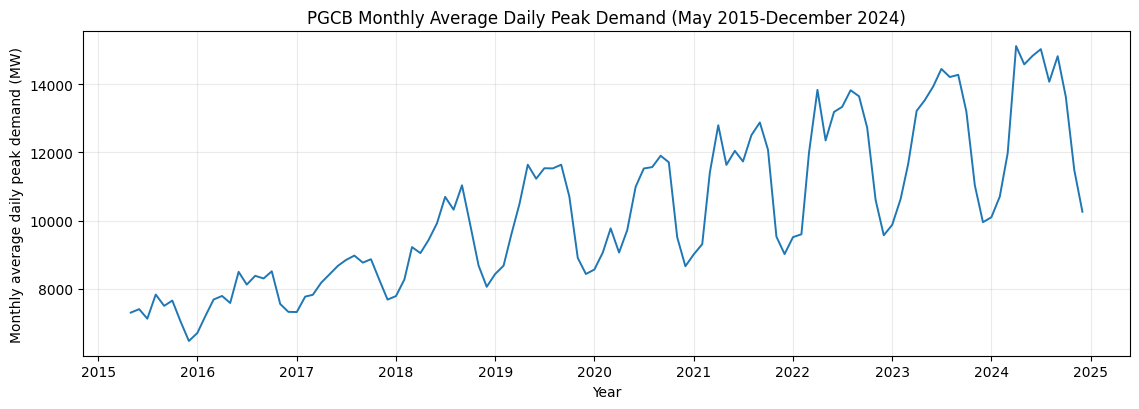

In [6]:
fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.plot(series.index, series.values, linewidth=1.4)
ax.set_xlabel('Year')
ax.set_ylabel('Monthly average daily peak demand (MW)')
ax.set_title('PGCB Monthly Average Daily Peak Demand (May 2015-December 2024)')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT_DIR / 'sarimax_fig1_monthly_peak_series_600dpi.png', dpi=FIG_DPI, bbox_inches='tight')
fig.savefig(OUT_DIR / 'sarimax_fig1_monthly_peak_series_vector.pdf', bbox_inches='tight')
plt.show()

## 7. Stationarity analysis with the Augmented Dickey-Fuller test
The ADF test is performed only on the pre-2024 training period. Results are reported for the raw monthly series, first difference, 12-month seasonal difference, and combined first-plus-seasonal difference. The null hypothesis is a unit root (non-stationarity).

In [7]:
train = series.loc[:TRAIN_END].copy()
test = series.loc[TEST_START:TEST_END].copy()
assert len(test) == 12 and test.notna().all()

adf_inputs = {
    'Raw monthly series': train,
    'First difference': train.diff(),
    'Seasonal difference (12)': train.diff(SEASONAL_PERIOD),
    'First + seasonal difference': train.diff().diff(SEASONAL_PERIOD),
}
adf_rows = []
for label, values in adf_inputs.items():
    stat, pval, used_lag, nobs, crit, icbest = adfuller(values.dropna(), autolag='AIC')
    adf_rows.append({
        'series': label,
        'adf_statistic': stat,
        'p_value': pval,
        'used_lag': used_lag,
        'n_observations': nobs,
        'critical_1pct': crit['1%'],
        'critical_5pct': crit['5%'],
        'critical_10pct': crit['10%'],
    })
ADF_RESULTS = pd.DataFrame(adf_rows)
ADF_RESULTS.to_csv(OUT_DIR / 'sarimax_adf_results.csv', index=False)
print(ADF_RESULTS.round(6).to_string(index=False))

                     series  adf_statistic  p_value  used_lag  n_observations  critical_1pct  critical_5pct  critical_10pct
         Raw monthly series      -0.684889 0.850625        12              91      -3.504343      -2.893866       -2.584015
           First difference      -5.272871 0.000006        11              91      -3.504343      -2.893866       -2.584015
   Seasonal difference (12)      -5.000756 0.000022         0              91      -3.504343      -2.893866       -2.584015
First + seasonal difference      -4.557081 0.000155        11              79      -3.515977      -2.898886       -2.586694


## 8. Chronological train-test split and simple baselines
The 12 months of 2024 are held out as the evaluation period, matching the structure of the professor-provided monthly example. Two transparent baselines are retained:

- **Naive:** December 2023 repeated for all 12 forecast months.
- **Seasonal naive:** the corresponding monthly values from January-December 2023.

Neither baseline uses 2024 actual demand to construct its predictions.

In [8]:
print('Training period:', train.index.min().date(), 'to', train.index.max().date(), '| months:', len(train))
print('Test period:', test.index.min().date(), 'to', test.index.max().date(), '| months:', len(test))

naive_forecast = np.repeat(train.iloc[-1], len(test))
seasonal_naive_forecast = train.iloc[-SEASONAL_PERIOD:].to_numpy(dtype=float)
assert len(seasonal_naive_forecast) == len(test)

Training period: 2015-05-01 to 2023-12-01 | months: 104
Test period: 2024-01-01 to 2024-12-01 | months: 12


## 9. Select SARIMAX order by training-only AIC
Search a modest candidate grid without consulting 2024 outcomes. The differencing structure is fixed at `d=1`, `D=1`, and the seasonal period is 12 months. Candidate autoregressive and moving-average orders are selected using the lowest Akaike Information Criterion (AIC) on the 2015-2023 training series.

This keeps the model-selection rule transparent and computationally light enough for a standard Colab CPU runtime.

In [9]:
search_rows = []
start = time.perf_counter()
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    order = (p, 1, q)
    seasonal_order = (P, 1, Q, SEASONAL_PERIOD)
    try:
        fitted = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(disp=False, maxiter=250)
        search_rows.append({
            'order': str(order),
            'seasonal_order': str(seasonal_order),
            'aic': float(fitted.aic),
            'bic': float(fitted.bic),
            'converged': bool(fitted.mle_retvals.get('converged', False)),
        })
    except Exception as exc:
        search_rows.append({
            'order': str(order),
            'seasonal_order': str(seasonal_order),
            'aic': np.nan,
            'bic': np.nan,
            'converged': False,
            'error': str(exc)[:200],
        })

MODEL_SEARCH = pd.DataFrame(search_rows).sort_values('aic', na_position='last').reset_index(drop=True)
MODEL_SEARCH.to_csv(OUT_DIR / 'sarimax_model_selection_aic.csv', index=False)
valid_models = MODEL_SEARCH.loc[MODEL_SEARCH['aic'].notna() & MODEL_SEARCH['converged']]
if valid_models.empty:
    raise RuntimeError('No candidate SARIMAX model converged.')

best = valid_models.iloc[0]
BEST_ORDER = tuple(int(x.strip()) for x in best['order'].strip('()').split(','))
BEST_SEASONAL_ORDER = tuple(int(x.strip()) for x in best['seasonal_order'].strip('()').split(','))

print('Candidate models evaluated:', len(MODEL_SEARCH))
print('Search time (s):', round(time.perf_counter() - start, 2))
print('\nTop 10 models by training AIC:')
print(MODEL_SEARCH.head(10).to_string(index=False))
print('\nSelected order:', BEST_ORDER)
print('Selected seasonal order:', BEST_SEASONAL_ORDER)

Candidate models evaluated: 36
Search time (s): 13.51

Top 10 models by training AIC:
    order seasonal_order         aic         bic  converged
(1, 1, 2)  (0, 1, 1, 12) 1189.463914 1201.117581       True
(1, 1, 2)  (1, 1, 1, 12) 1191.463253 1205.447653       True
(2, 1, 2)  (1, 1, 1, 12) 1192.884518 1209.199652       True
(2, 1, 2)  (0, 1, 1, 12) 1193.084488 1207.068888       True
(0, 1, 2)  (0, 1, 1, 12) 1193.741241 1203.064174       True
(0, 1, 2)  (1, 1, 1, 12) 1195.736575 1207.390242       True
(1, 1, 1)  (0, 1, 1, 12) 1202.738926 1212.114147       True
(2, 1, 1)  (0, 1, 1, 12) 1204.087498 1215.806525       True
(1, 1, 1)  (1, 1, 1, 12) 1204.729408 1216.448436       True
(2, 1, 1)  (1, 1, 1, 12) 1206.060285 1220.123117       True

Selected order: (1, 1, 2)
Selected seasonal order: (0, 1, 1, 12)


## 10. Fit the selected SARIMAX model and forecast 2024
Refit the AIC-selected specification on the entire pre-2024 training series, then generate a 12-month forecast with 95% prediction intervals. No 2024 actual value is used for fitting or order selection in this notebook.

In [10]:
FINAL_MODEL = SARIMAX(
    train,
    order=BEST_ORDER,
    seasonal_order=BEST_SEASONAL_ORDER,
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False, maxiter=400)

forecast_result = FINAL_MODEL.get_forecast(steps=len(test))
sarimax_forecast = forecast_result.predicted_mean
ci = forecast_result.conf_int(alpha=0.05)
ci.columns = ['lower_95_mw', 'upper_95_mw']

FORECAST_TABLE = pd.DataFrame({
    'actual_mw': test,
    'naive_mw': naive_forecast,
    'seasonal_naive_mw': seasonal_naive_forecast,
    'sarimax_forecast_mw': sarimax_forecast,
    'lower_95_mw': ci['lower_95_mw'],
    'upper_95_mw': ci['upper_95_mw'],
})
FORECAST_TABLE.index.name = 'month'
FORECAST_TABLE.to_csv(OUT_DIR / 'sarimax_forecast_2024.csv')
print(FINAL_MODEL.summary())

                                      SARIMAX Results                                       
Dep. Variable:            monthly_avg_daily_peak_mw   No. Observations:                  104
Model:             SARIMAX(1, 1, 2)x(0, 1, [1], 12)   Log Likelihood                -589.732
Date:                              Wed, 11 Nov 2026   AIC                           1189.464
Time:                                      06:37:50   BIC                           1201.118
Sample:                                  05-01-2015   HQIC                          1194.121
                                       - 12-01-2023                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4774      0.178      2.679      0.007       0.128       0.827
ma.L1         -0.85

## 11. Evaluate SARIMAX against the two baselines
Report MAE, RMSE, MAPE, and 95% interval coverage for the 12 evaluation months. The manuscript should use the actual numbers produced by your Colab run, not values copied from another dataset or from the example notebook.

In [11]:
def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        'MAE_MW': mean_absolute_error(y_true, y_pred),
        'RMSE_MW': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE_pct': 100 * np.mean(np.abs((y_true - y_pred) / y_true)),
    }

metric_rows = []
for name, pred in [
    ('Naive', naive_forecast),
    ('Seasonal Naive (12-month)', seasonal_naive_forecast),
    (f'SARIMAX{BEST_ORDER}x{BEST_SEASONAL_ORDER}', sarimax_forecast),
]:
    row = {'method': name, **evaluate(test, pred)}
    metric_rows.append(row)

RESULTS = pd.DataFrame(metric_rows)
coverage_95 = 100 * np.mean((test >= ci['lower_95_mw']) & (test <= ci['upper_95_mw']))
RESULTS['test_months'] = len(test)
RESULTS.to_csv(OUT_DIR / 'sarimax_results_2024.csv', index=False)

print(RESULTS.round(3).to_string(index=False))
print('\nSARIMAX 95% prediction-interval coverage on the 12 test months:', round(coverage_95, 2), '%')

                        method   MAE_MW  RMSE_MW  MAPE_pct  test_months
                         Naive 3099.425 3641.711    21.953           12
     Seasonal Naive (12-month)  575.818  753.490     4.159           12
SARIMAX(1, 1, 2)x(0, 1, 1, 12)  505.604  558.397     3.955           12

SARIMAX 95% prediction-interval coverage on the 12 test months: 100.0 %


## 12. Manuscript-ready actual-vs-forecast figure
Plot the final 36 training months for context, the 12 observed 2024 monthly values, the SARIMAX forecast, and its 95% prediction interval. This is the recommended SARIMAX figure for the IEEE manuscript because it directly communicates the model's time-series fit and out-of-sample forecasting behavior.

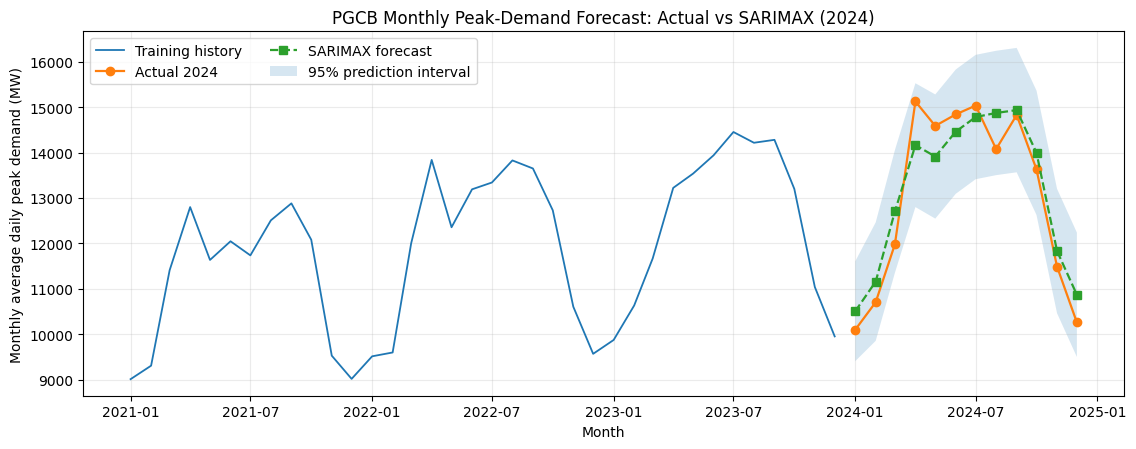

In [12]:
fig, ax = plt.subplots(figsize=(11.5, 4.6))
context = train.iloc[-36:]
ax.plot(context.index, context.values, linewidth=1.3, label='Training history')
ax.plot(test.index, test.values, marker='o', linewidth=1.6, label='Actual 2024')
ax.plot(test.index, sarimax_forecast.values, marker='s', linestyle='--', linewidth=1.6,
        label='SARIMAX forecast')
ax.fill_between(test.index, ci['lower_95_mw'].values, ci['upper_95_mw'].values,
                alpha=0.18, label='95% prediction interval')
ax.set_xlabel('Month')
ax.set_ylabel('Monthly average daily peak demand (MW)')
ax.set_title('PGCB Monthly Peak-Demand Forecast: Actual vs SARIMAX (2024)')
ax.legend(ncol=2)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT_DIR / 'sarimax_fig2_actual_vs_forecast_2024_600dpi.png', dpi=FIG_DPI, bbox_inches='tight')
fig.savefig(OUT_DIR / 'sarimax_fig2_actual_vs_forecast_2024_vector.pdf', bbox_inches='tight')
plt.show()

## 13. Residual diagnostics
Save the standard SARIMAX diagnostic panel and Ljung-Box statistics. These diagnostics help identify remaining autocorrelation or distributional problems and should be reviewed before making strong claims about model adequacy.

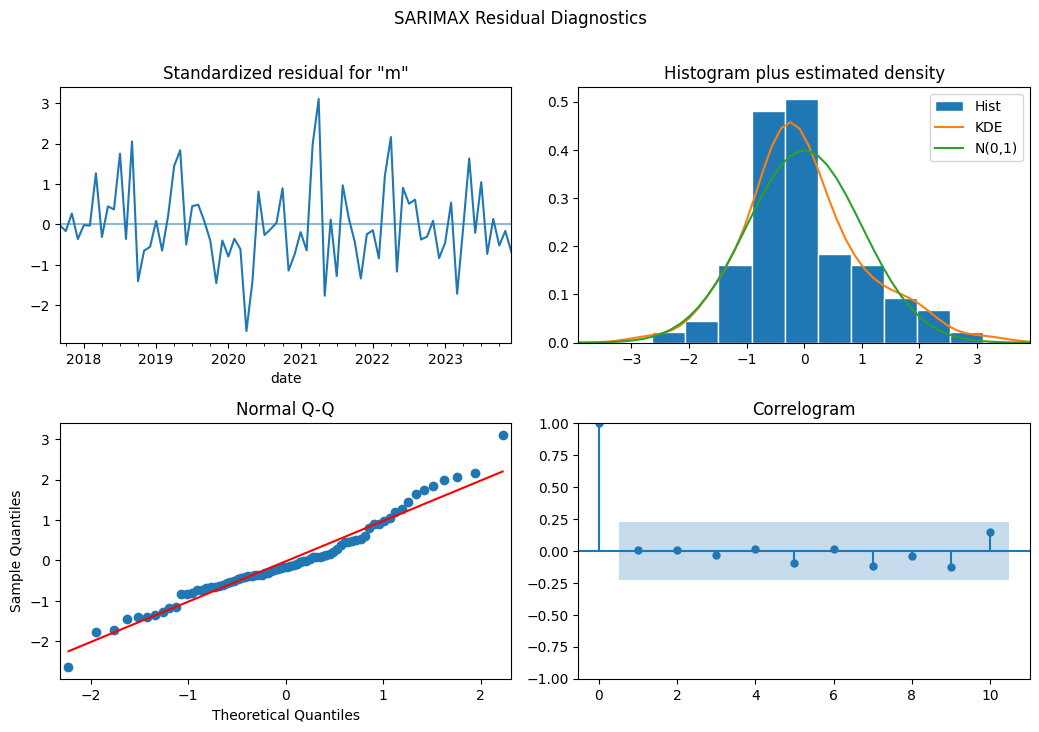

 lag   lb_stat  lb_pvalue
  12 21.254516   0.046775
  24 26.207805   0.342706


In [13]:
fig = FINAL_MODEL.plot_diagnostics(figsize=(10.5, 7.2))
fig.suptitle('SARIMAX Residual Diagnostics', y=1.01)
fig.tight_layout()
fig.savefig(OUT_DIR / 'sarimax_fig3_residual_diagnostics_600dpi.png', dpi=FIG_DPI, bbox_inches='tight')
fig.savefig(OUT_DIR / 'sarimax_fig3_residual_diagnostics_vector.pdf', bbox_inches='tight')
plt.show()

resid = pd.Series(FINAL_MODEL.resid).dropna()
LJUNG_BOX = acorr_ljungbox(resid, lags=[12, 24], return_df=True).reset_index(names='lag')
LJUNG_BOX.to_csv(OUT_DIR / 'sarimax_ljung_box.csv', index=False)
print(LJUNG_BOX.round(6).to_string(index=False))

## 14. Save the full experimental protocol and a manuscript-ready text summary
The protocol records the dataset fingerprint, preprocessing, target definition, split, model-selection rule, selected SARIMAX specification, metrics, and limitations. The text file provides a concise summary to use when updating the manuscript **after verifying the Colab outputs**.

In [14]:
sarimax_row = RESULTS.loc[RESULTS['method'].str.startswith('SARIMAX')].iloc[0]
protocol = {
    'paper_title': 'An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids',
    'experiment': 'Monthly peak-demand time-series analysis using SARIMAX',
    'source_dataset': 'PGCB Hourly Generation Dataset (Bangladesh), UCI #1175',
    'source_sha256': SOURCE_SHA256,
    'target': 'monthly average of daily maximum hourly demand, MW',
    'daily_eligibility': 'exactly 24 unique valid on-hour readings',
    'monthly_start': str(MONTHLY_START.date()),
    'training_end': str(TRAIN_END.date()),
    'evaluation_period': '2024-01 through 2024-12',
    'training_months': int(len(train)),
    'test_months': int(len(test)),
    'seasonal_period_months': SEASONAL_PERIOD,
    'model_selection': 'lowest AIC among p,q=0..2 and P,Q=0..1 with d=D=1, using training data only',
    'selected_order': BEST_ORDER,
    'selected_seasonal_order': BEST_SEASONAL_ORDER,
    'selected_aic': float(FINAL_MODEL.aic),
    'sarimax_mae_mw': float(sarimax_row['MAE_MW']),
    'sarimax_rmse_mw': float(sarimax_row['RMSE_MW']),
    'sarimax_mape_pct': float(sarimax_row['MAPE_pct']),
    'prediction_interval_coverage_pct': float(coverage_95),
    'figure_export_dpi': FIG_DPI,
    'limitations': [
        'This is a monthly aggregate time-series experiment and is not directly comparable to the hourly Ridge forecasting metrics.',
        'The target is the monthly average of daily peak demand on eligible complete days, not every operating day.',
        'The 2024 period has been inspected in earlier project phases and is therefore not a pristine external holdout.',
        'SARIMAX forecasting does not demonstrate actual load-shedding prevention or physical demand flexibility.',
    ],
}
(OUT_DIR / 'sarimax_protocol.json').write_text(json.dumps(protocol, indent=2, default=str))

summary_text = f"""SARIMAX TIME-SERIES EXPERIMENT SUMMARY

Target: monthly average daily peak demand (MW)
Training: {train.index.min().strftime('%Y-%m')} to {train.index.max().strftime('%Y-%m')} ({len(train)} months)
Evaluation: 2024-01 to 2024-12 ({len(test)} months)
Selected model: SARIMAX{BEST_ORDER} x {BEST_SEASONAL_ORDER}
Training AIC: {FINAL_MODEL.aic:.3f}
SARIMAX MAE: {sarimax_row['MAE_MW']:.3f} MW
SARIMAX RMSE: {sarimax_row['RMSE_MW']:.3f} MW
SARIMAX MAPE: {sarimax_row['MAPE_pct']:.3f}%
95% interval coverage: {coverage_95:.2f}%

Interpretation note: These metrics refer to a monthly aggregate peak-demand time-series task and must not be compared directly with the hourly Ridge metrics without explicitly noting the different target and temporal resolution.
"""
(OUT_DIR / 'sarimax_manuscript_summary.txt').write_text(summary_text)
print(summary_text)

SARIMAX TIME-SERIES EXPERIMENT SUMMARY

Target: monthly average daily peak demand (MW)
Training: 2015-05 to 2023-12 (104 months)
Evaluation: 2024-01 to 2024-12 (12 months)
Selected model: SARIMAX(1, 1, 2) x (0, 1, 1, 12)
Training AIC: 1189.464
SARIMAX MAE: 505.604 MW
SARIMAX RMSE: 558.397 MW
SARIMAX MAPE: 3.955%
95% interval coverage: 100.00%

Interpretation note: These metrics refer to a monthly aggregate peak-demand time-series task and must not be compared directly with the hourly Ridge metrics without explicitly noting the different target and temporal resolution.

